# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Muhammad Fardan Hafidz | 5054251021 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **TensorFlow / Keras** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Mengatur environment dan filter warning
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')

# Import TensorFlow dan Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Import scikit-learn dan utilitas
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from IPython.display import display

# Set random seed agar hasil eksperimen dapat direproduksi
tf.keras.utils.set_random_seed(42)
np.random.seed(42)
random.seed(42)

# Konfigurasi global agar pengaturan ketiga model identik
EPOCHS = 20
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

print("Versi TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))
print("Semua library berhasil di-import dan random seed disetel ke 42.")


def plot_learning_curve(history, judul):
    '''Menampilkan kurva loss dan accuracy train vs validation.'''
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(history.history["loss"], label="Train", linewidth=2)
    axes[0].plot(history.history["val_loss"], label="Validation", linewidth=2)
    axes[0].set_title(f"Loss - {judul}", fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history.history["accuracy"], label="Train", linewidth=2)
    axes[1].plot(history.history["val_accuracy"], label="Validation", linewidth=2)
    axes[1].set_title(f"Accuracy - {judul}", fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Versi TensorFlow: 2.19.1
GPU tersedia: []
Semua library berhasil di-import dan random seed disetel ke 42.


In [2]:
# Load dataset train dan test dari file CSV
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

print("Ukuran data train :", train_df.shape)
print("Ukuran data test  :", test_df.shape)
print("Setiap baris terdiri dari 1 kolom label + 784 kolom piksel (28x28).")

print("\n5 baris pertama data train (8 kolom pertama):")
print(train_df.iloc[:5, :8])

print("\nJumlah missing value data train:", int(train_df.isnull().sum().sum()))
print("Jumlah missing value data test :", int(test_df.isnull().sum().sum()))

Ukuran data train : (60000, 785)
Ukuran data test  : (10000, 785)
Setiap baris terdiri dari 1 kolom label + 784 kolom piksel (28x28).

5 baris pertama data train (8 kolom pertama):
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7
0      2       0       0       0       0       0       0       0
1      9       0       0       0       0       0       0       0
2      6       0       0       0       0       0       0       0
3      0       0       0       0       1       2       0       0
4      3       0       0       0       0       0       0       0

Jumlah missing value data train: 0
Jumlah missing value data test : 0


Jumlah gambar per kelas pada data train:
  0 - T-shirt/top : 6000
  1 - Trouser     : 6000
  2 - Pullover    : 6000
  3 - Dress       : 6000
  4 - Coat        : 6000
  5 - Sandal      : 6000
  6 - Shirt       : 6000
  7 - Sneaker     : 6000
  8 - Bag         : 6000
  9 - Ankle boot  : 6000


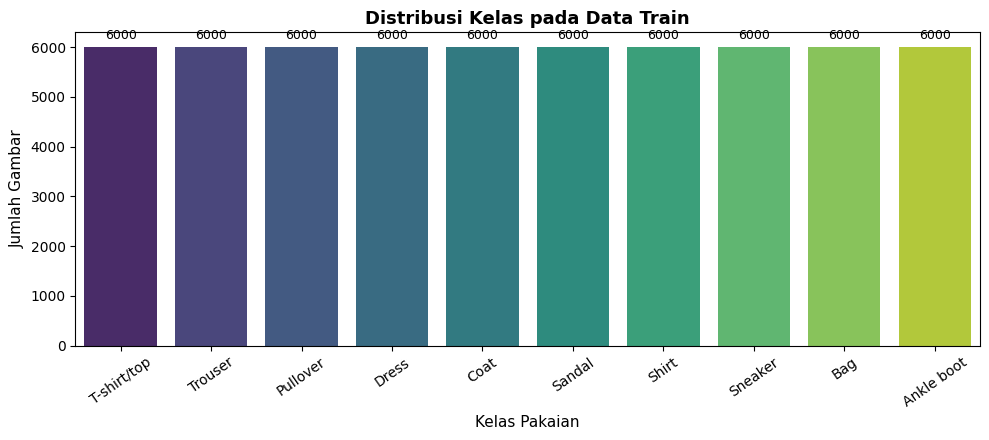

Dataset train bersifat BALANCED: setiap kelas berisi 6.000 gambar.


In [3]:
# Mapping label angka (0-9) ke nama kelas pakaian
class_names = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

class_counts = train_df['label'].value_counts().sort_index()

print("Jumlah gambar per kelas pada data train:")
for label, jumlah in class_counts.items():
    print(f"  {label} - {class_names[label]:<12}: {jumlah}")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(
    x=[class_names[i] for i in class_counts.index],
    y=class_counts.values,
    palette='viridis',
    ax=ax
)
ax.set_title('Distribusi Kelas pada Data Train', fontsize=13, fontweight='bold')
ax.set_xlabel('Kelas Pakaian', fontsize=11)
ax.set_ylabel('Jumlah Gambar', fontsize=11)
ax.tick_params(axis='x', rotation=35)

for p, nilai in zip(ax.patches, class_counts.values):
    ax.annotate(str(nilai), xy=(p.get_x() + p.get_width() / 2, nilai),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("Dataset train bersifat BALANCED: setiap kelas berisi 6.000 gambar.")

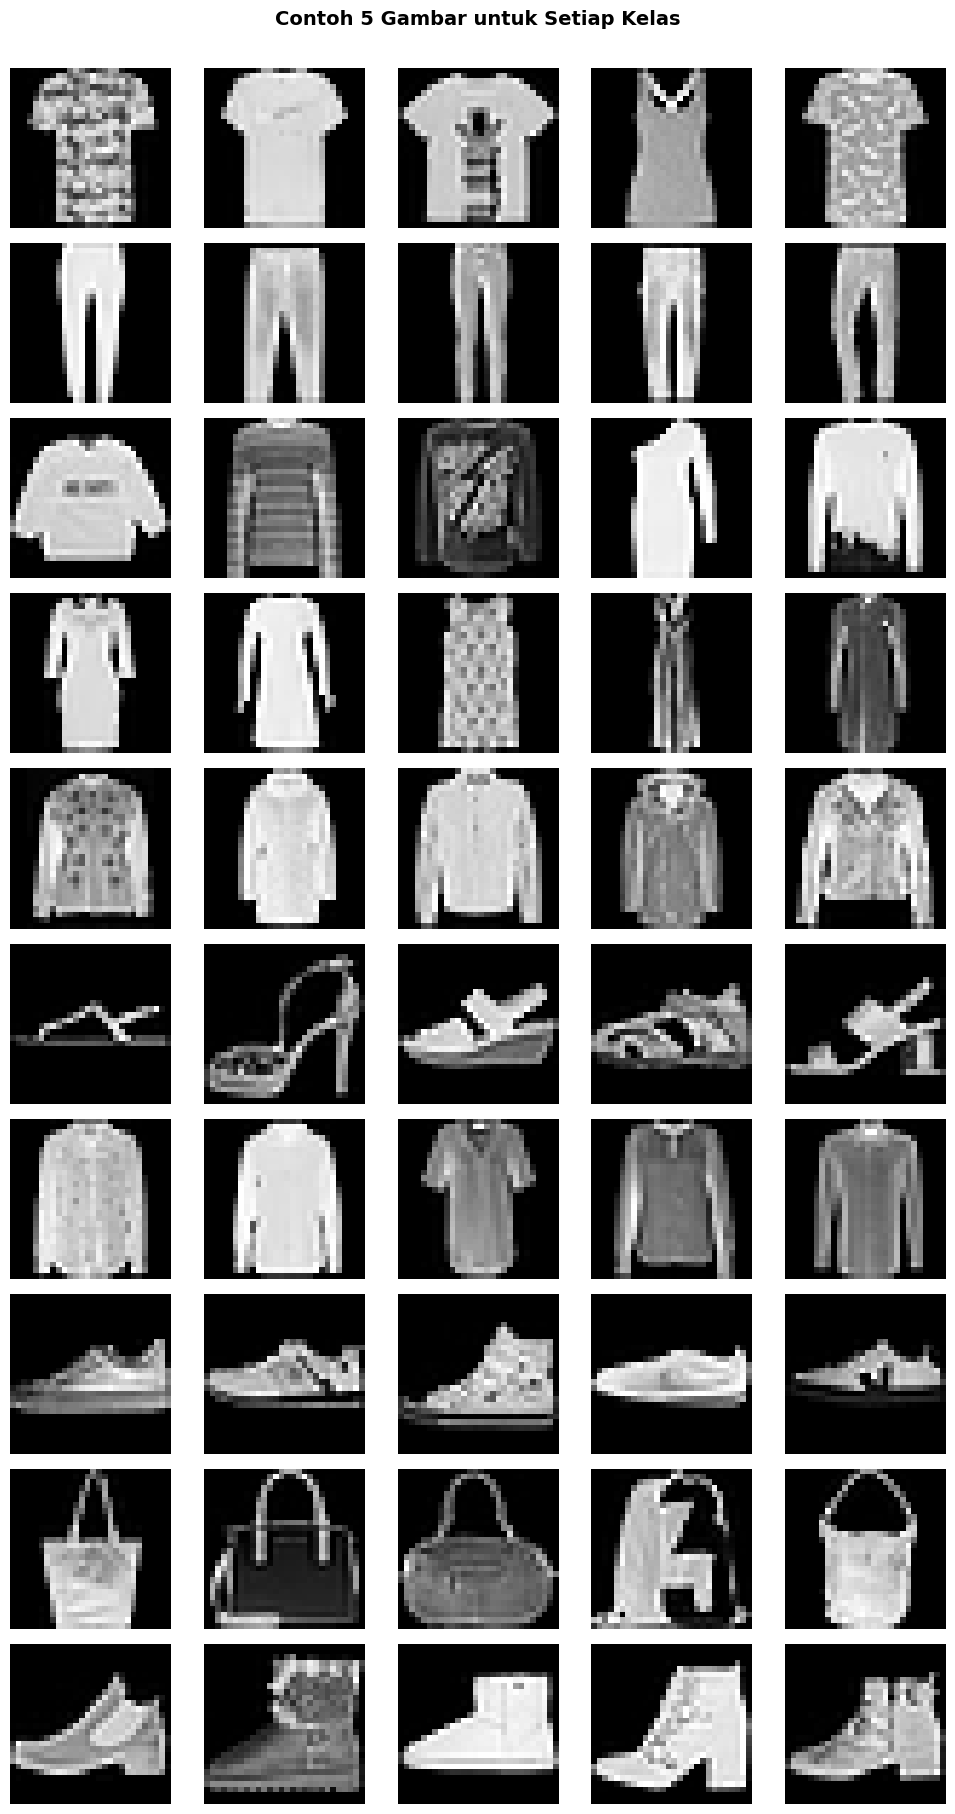

Kelas yang secara visual mirip: T-shirt/top, Pullover, Coat, dan Shirt (sesama atasan).
Sneaker, Sandal, dan Ankle boot juga memiliki siluet yang serupa.


In [4]:
# Tampilkan contoh gambar dari setiap kelas (grid 10 kelas x 5 gambar)
X_train_pixels = train_df.drop(columns=['label']).values.reshape(-1, 28, 28)
y_train_pixels = train_df['label'].values

fig, axes = plt.subplots(10, 5, figsize=(10, 18))
for kelas in range(10):
    idx_kelas = np.where(y_train_pixels == kelas)[0][:5]
    for j, idx in enumerate(idx_kelas):
        ax = axes[kelas, j]
        ax.imshow(X_train_pixels[idx], cmap='gray')
        ax.axis('off')
        if j == 0:
            ax.set_ylabel(class_names[kelas], fontsize=10,
                          rotation=0, labelpad=48, va='center')

fig.suptitle('Contoh 5 Gambar untuk Setiap Kelas', fontsize=14, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

print("Kelas yang secara visual mirip: T-shirt/top, Pullover, Coat, dan Shirt (sesama atasan).")
print("Sneaker, Sandal, dan Ankle boot juga memiliki siluet yang serupa.")

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

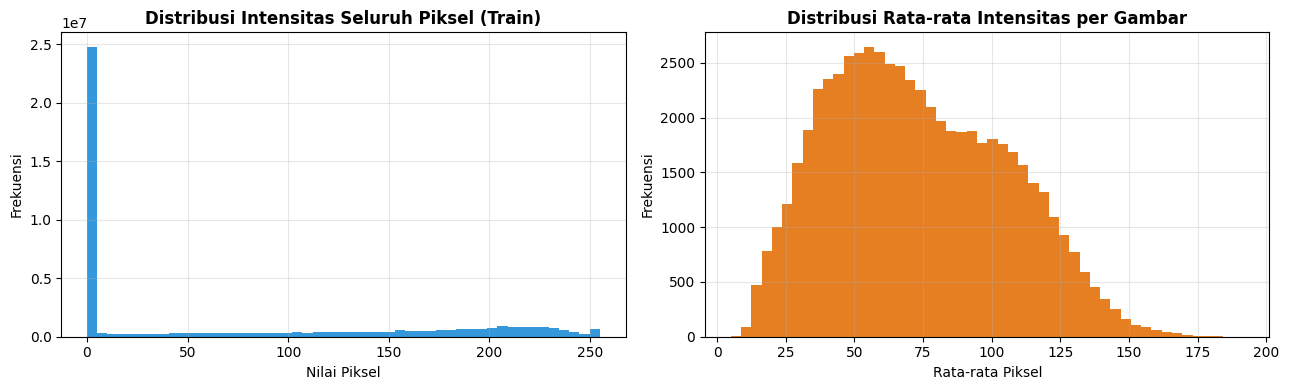

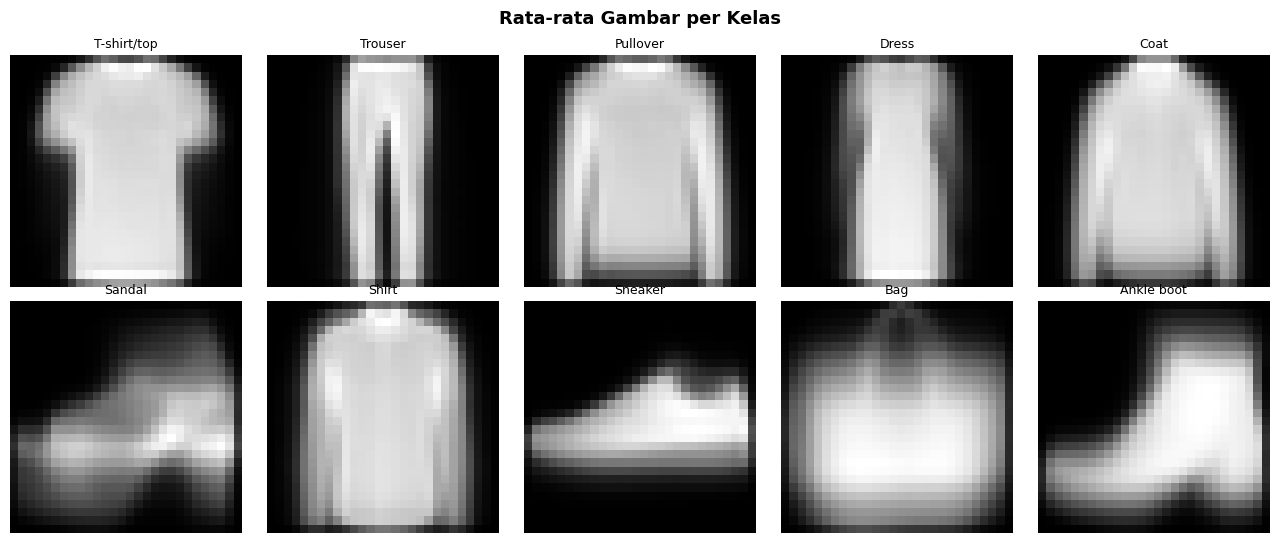

Proporsi piksel bernilai 0 (latar belakang): 50.2%


Rata-rata nilai piksel non-nol: 146.4
Sebagian besar piksel bernilai 0, sehingga objek pakaian berada di tengah dengan latar gelap.


In [5]:
# EDA tambahan 1: distribusi intensitas piksel
all_pixels = train_df.drop(columns=['label']).values

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(all_pixels.ravel(), bins=50, color='#3498db')
axes[0].set_title('Distribusi Intensitas Seluruh Piksel (Train)', fontweight='bold')
axes[0].set_xlabel('Nilai Piksel')
axes[0].set_ylabel('Frekuensi')
axes[0].grid(alpha=0.3)

axes[1].hist(all_pixels.mean(axis=1), bins=50, color='#e67e22')
axes[1].set_title('Distribusi Rata-rata Intensitas per Gambar', fontweight='bold')
axes[1].set_xlabel('Rata-rata Piksel')
axes[1].set_ylabel('Frekuensi')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# EDA tambahan 2: rata-rata gambar tiap kelas
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for kelas, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_pixels[y_train_pixels == kelas].mean(axis=0), cmap='gray')
    ax.set_title(class_names[kelas], fontsize=9)
    ax.axis('off')
fig.suptitle('Rata-rata Gambar per Kelas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Proporsi piksel bernilai 0 (latar belakang): {(all_pixels == 0).mean() * 100:.1f}%")
print(f"Rata-rata nilai piksel non-nol: {all_pixels[all_pixels > 0].mean():.1f}")
print("Sebagian besar piksel bernilai 0, sehingga objek pakaian berada di tengah dengan latar gelap.")

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di TensorFlow/Keras, urutan dimensi gambar adalah **(batch, tinggi, lebar, channel)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)` |
| CNN | `(N, 28, 28, 1)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test
y_train_full = train_df['label'].values
X_train_full = train_df.drop(columns=['label']).values

y_test = test_df['label'].values
X_test_full = test_df.drop(columns=['label']).values

print("X_train_full:", X_train_full.shape, "| y_train_full:", y_train_full.shape)
print("X_test_full :", X_test_full.shape, "| y_test     :", y_test.shape)

X_train_full: (60000, 784) | y_train_full: (60000,)
X_test_full : (10000, 784) | y_test     : (10000,)


In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255)
X_train_full = X_train_full / 255.0
X_test_full = X_test_full / 255.0

print("Rentang nilai piksel setelah normalisasi:")
print("  min:", X_train_full.min(), "| max:", X_train_full.max())

Rentang nilai piksel setelah normalisasi:


  min: 0.0 | max: 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (90:10) dengan stratify
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.10, random_state=42, stratify=y_train_full
)

print("Jumlah data train      :", X_train.shape[0])
print("Jumlah data validation :", X_val.shape[0])
print("Jumlah data test       :", X_test_full.shape[0])
print("Distribusi kelas validation (harus proporsional):", np.bincount(y_val).tolist())

Jumlah data train      : 54000
Jumlah data validation : 6000
Jumlah data test       : 10000
Distribusi kelas validation (harus proporsional): [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]


In [9]:
# Ubah bentuk data sesuai kebutuhan model dan pastikan bertipe float32
# ANN : (N, 784)        -> gambar di-flatten
# CNN : (N, 28, 28, 1)  -> tetap 2D dengan 1 channel grayscale
X_train_ann = X_train.reshape(-1, 784).astype('float32')
X_val_ann = X_val.reshape(-1, 784).astype('float32')
X_test_ann = X_test_full.reshape(-1, 784).astype('float32')

X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype('float32')
X_val_cnn = X_val.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test_full.reshape(-1, 28, 28, 1).astype('float32')

print("X_train_ann:", X_train_ann.shape, "| dtype:", X_train_ann.dtype)
print("X_train_cnn:", X_train_cnn.shape, "| dtype:", X_train_cnn.dtype)

X_train_ann: (54000, 784) | dtype: float32
X_train_cnn: (54000, 28, 28, 1) | dtype: float32


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output dengan aktivasi Softmax** dan **`sparse_categorical_crossentropy`** sebagai loss function (label berupa angka 0-9).

Contoh arsitektur: `Input(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax)`

In [10]:
# Definisikan arsitektur ANN menggunakan keras.Sequential
ann_model = keras.Sequential([
    keras.Input(shape=(784,), name='input_ann'),
    layers.Dense(256, activation='relu', name='hidden_1'),
    layers.Dense(128, activation='relu', name='hidden_2'),
    layers.Dense(10, activation='softmax', name='output')
], name='ann_baseline')

ann_model.summary()

Model: "ann_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Compile model dan latih dengan validation_data
early_stop_ann = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)

ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_ann = ann_model.fit(
    X_train_ann, y_train,
    validation_data=(X_val_ann, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_ann],
    verbose=2
)

Epoch 1/20


422/422 - 2s - 6ms/step - accuracy: 0.8154 - loss: 0.5209 - val_accuracy: 0.8517 - val_loss: 0.4217


Epoch 2/20


422/422 - 1s - 3ms/step - accuracy: 0.8634 - loss: 0.3787 - val_accuracy: 0.8705 - val_loss: 0.3686


Epoch 3/20


422/422 - 1s - 3ms/step - accuracy: 0.8786 - loss: 0.3360 - val_accuracy: 0.8768 - val_loss: 0.3403


... (8 outputs left out)

Epoch 8/20


422/422 - 1s - 3ms/step - accuracy: 0.9085 - loss: 0.2465 - val_accuracy: 0.8773 - val_loss: 0.3491


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 5.


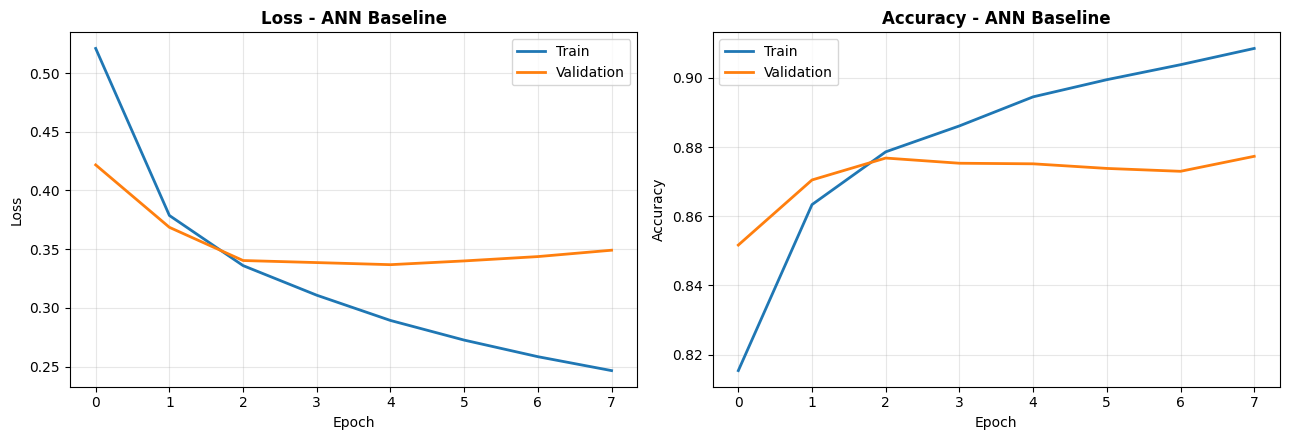

In [12]:
# Tampilkan learning curve ANN
plot_learning_curve(history_ann, 'ANN Baseline')

In [13]:
# Prediksi pada test set: ambil kelas dengan probabilitas terbesar
y_pred_proba_ann = ann_model.predict(X_test_ann, verbose=0)
y_pred_ann = np.argmax(y_pred_proba_ann, axis=1)

print("Contoh 10 label asli    :", y_test[:10])
print("Contoh 10 label prediksi:", y_pred_ann[:10])

Contoh 10 label asli    : [0 1 2 2 3 2 8 6 5 0]
Contoh 10 label prediksi: [6 1 2 2 4 6 8 4 5 0]


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2D (ReLU) → MaxPooling, lalu dilanjutkan Flatten dan Dense.

Contoh arsitektur: `[Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2)] → [Conv2D(64, 3×3, ReLU) → MaxPooling2D(2×2)] → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`

In [14]:
# Definisikan arsitektur CNN sederhana
cnn_model = keras.Sequential([
    keras.Input(shape=(28, 28, 1), name='input_cnn'),
    layers.Conv2D(32, (3, 3), activation='relu', padding='valid', name='conv_1'),
    layers.MaxPooling2D((2, 2), name='pool_1'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='valid', name='conv_2'),
    layers.MaxPooling2D((2, 2), name='pool_2'),
    layers.Flatten(name='flatten'),
    layers.Dense(128, activation='relu', name='dense_1'),
    layers.Dense(10, activation='softmax', name='output')
], name='cnn_sederhana')

cnn_model.summary()

# Perhitungan manual ukuran output setiap layer: (W - K + 2P) / S + 1
print("\nPerhitungan manual ukuran output (padding='valid' -> P=0, stride=1):")
print("Input                       : 28 x 28 x 1")
print("Conv2D 3x3                  : (28 - 3 + 0)/1 + 1 = 26 -> 26 x 26 x 32")
print("MaxPooling 2x2 (stride 2)   : (26 - 2)/2 + 1     = 13 -> 13 x 13 x 32")
print("Conv2D 3x3                  : (13 - 3 + 0)/1 + 1 = 11 -> 11 x 11 x 64")
print("MaxPooling 2x2 (stride 2)   : (11 - 2)//2 + 1    = 5  -> 5 x 5 x 64")
print("Flatten                     : 5 x 5 x 64 = 1600")
print("Hasil di atas cocok dengan kolom Output Shape pada model.summary().")

Model: "cnn_sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)


Perhitungan manual ukuran output (padding='valid' -> P=0, stride=1):
Input                       : 28 x 28 x 1
Conv2D 3x3                  : (28 - 3 + 0)/1 + 1 = 26 -> 26 x 26 x 32
MaxPooling 2x2 (stride 2)   : (26 - 2)/2 + 1     = 13 -> 13 x 13 x 32
Conv2D 3x3                  : (13 - 3 + 0)/1 + 1 = 11 -> 11 x 11 x 64
MaxPooling 2x2 (stride 2)   : (11 - 2)//2 + 1    = 5  -> 5 x 5 x 64
Flatten                     : 5 x 5 x 64 = 1600
Hasil di atas cocok dengan kolom Output Shape pada model.summary().


Epoch 1/20


422/422 - 14s - 32ms/step - accuracy: 0.8007 - loss: 0.5557 - val_accuracy: 0.8640 - val_loss: 0.3871


Epoch 2/20


422/422 - 13s - 30ms/step - accuracy: 0.8688 - loss: 0.3597 - val_accuracy: 0.8815 - val_loss: 0.3329


Epoch 3/20


422/422 - 13s - 31ms/step - accuracy: 0.8866 - loss: 0.3097 - val_accuracy: 0.8912 - val_loss: 0.3042


... (16 outputs left out)

Epoch 12/20


422/422 - 13s - 31ms/step - accuracy: 0.9486 - loss: 0.1417 - val_accuracy: 0.9027 - val_loss: 0.2804


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 9.


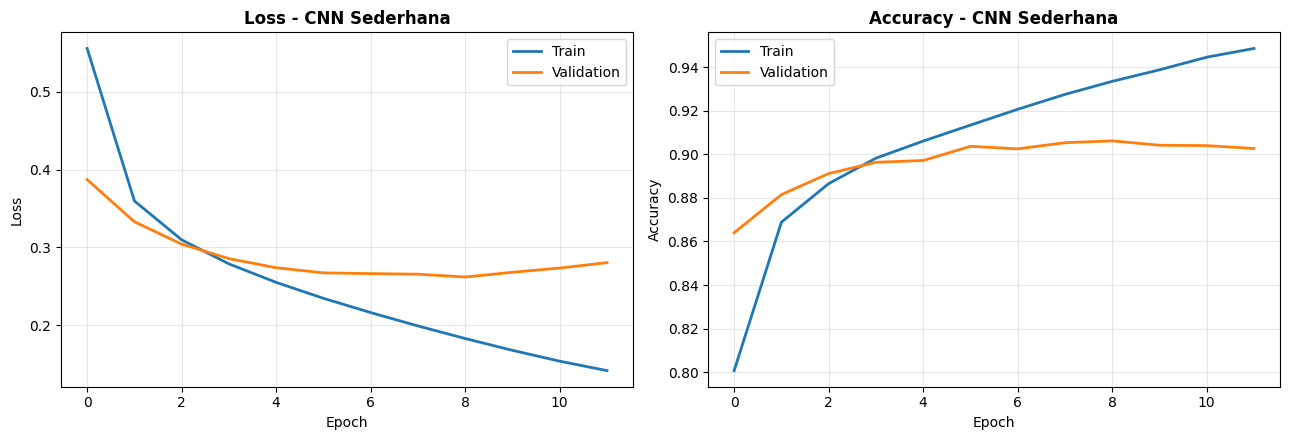

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1
early_stop_cnn = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_cnn = cnn_model.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_cnn],
    verbose=2
)

plot_learning_curve(history_cnn, 'CNN Sederhana')

In [16]:
# Prediksi pada test set
y_pred_proba_cnn = cnn_model.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(y_pred_proba_cnn, axis=1)

print("Contoh 10 label asli    :", y_test[:10])
print("Contoh 10 label prediksi:", y_pred_cnn[:10])

Contoh 10 label asli    : [0 1 2 2 3 2 8 6 5 0]
Contoh 10 label prediksi: [0 1 2 6 3 6 8 6 5 0]


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout
cnn_bn_model = keras.Sequential([
    keras.Input(shape=(28, 28, 1), name='input_cnn_bn'),
    layers.Conv2D(32, (3, 3), padding='valid', use_bias=False, name='conv_1'),
    layers.BatchNormalization(name='bn_1'),
    layers.Activation('relu', name='relu_1'),
    layers.MaxPooling2D((2, 2), name='pool_1'),
    layers.Conv2D(64, (3, 3), padding='valid', use_bias=False, name='conv_2'),
    layers.BatchNormalization(name='bn_2'),
    layers.Activation('relu', name='relu_2'),
    layers.MaxPooling2D((2, 2), name='pool_2'),
    layers.Flatten(name='flatten'),
    layers.Dense(128, activation='relu', name='dense_1'),
    layers.Dropout(0.4, name='dropout'),
    layers.Dense(10, activation='softmax', name='output')
], name='cnn_bn_dropout')

cnn_bn_model.summary()

Model: "cnn_bn_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 26, 26, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 26, 26, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 11, 11, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 11, 11, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,322 (880.16 KB)

 Trainable params: 225,130 (879.41 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/20


422/422 - 26s - 62ms/step - accuracy: 0.7988 - loss: 0.5624 - val_accuracy: 0.7347 - val_loss: 0.6867


Epoch 2/20


422/422 - 25s - 59ms/step - accuracy: 0.8608 - loss: 0.3884 - val_accuracy: 0.8613 - val_loss: 0.3477


Epoch 3/20


422/422 - 25s - 59ms/step - accuracy: 0.8774 - loss: 0.3380 - val_accuracy: 0.8858 - val_loss: 0.3063


... (18 outputs left out)

Epoch 13/20


422/422 - 25s - 59ms/step - accuracy: 0.9300 - loss: 0.1868 - val_accuracy: 0.9073 - val_loss: 0.2687


Epoch 13: early stopping


Restoring model weights from the end of the best epoch: 10.


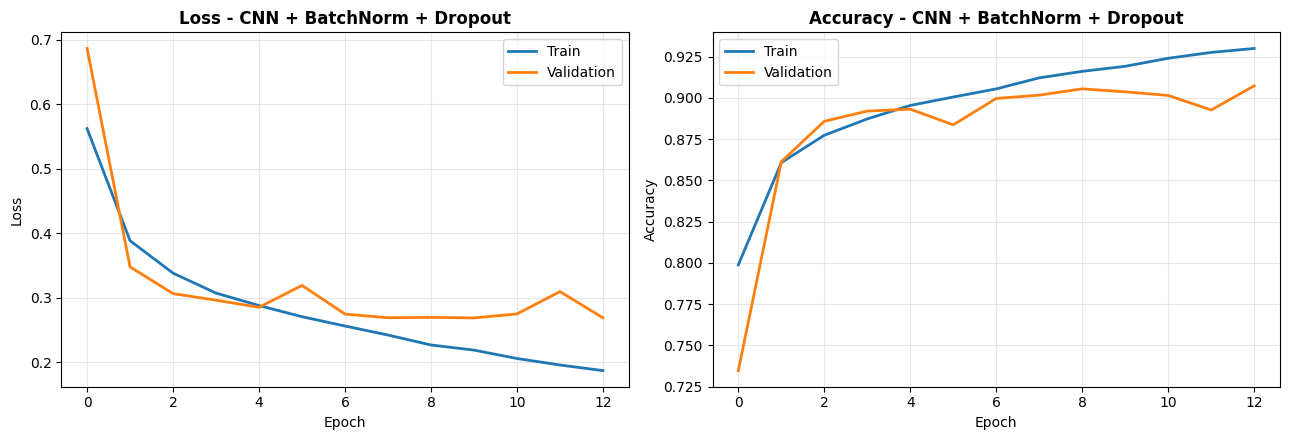

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2
early_stop_bn = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)

cnn_bn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_cnn_bn = cnn_bn_model.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_bn],
    verbose=2
)

plot_learning_curve(history_cnn_bn, 'CNN + BatchNorm + Dropout')

In [19]:
# Prediksi pada test set
y_pred_proba_cnn_bn = cnn_bn_model.predict(X_test_cnn, verbose=0)
y_pred_cnn_bn = np.argmax(y_pred_proba_cnn_bn, axis=1)

print("Contoh 10 label asli    :", y_test[:10])
print("Contoh 10 label prediksi:", y_pred_cnn_bn[:10])

Contoh 10 label asli    : [0 1 2 2 3 2 8 6 5 0]
Contoh 10 label prediksi: [0 1 2 6 3 6 8 6 5 0]


# 4. Evaluasi Model

In [20]:
# Tabel perbandingan metrik evaluasi seluruh model
models_info = [
    ('ANN Baseline', ann_model, y_pred_ann),
    ('CNN Sederhana', cnn_model, y_pred_cnn),
    ('CNN + BatchNorm + Dropout', cnn_bn_model, y_pred_cnn_bn),
]

rows = []
for nama, model, y_pred in models_info:
    rows.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (Macro)': precision_score(y_test, y_pred, average='macro'),
        'Recall (Macro)': recall_score(y_test, y_pred, average='macro'),
        'F1-Score (Macro)': f1_score(y_test, y_pred, average='macro'),
        'Jumlah Parameter': model.count_params()
    })

results_df = pd.DataFrame(rows).set_index('Model')
display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision (Macro)': '{:.4f}',
    'Recall (Macro)': '{:.4f}',
    'F1-Score (Macro)': '{:.4f}',
    'Jumlah Parameter': '{:,}'
}))

print(results_df.round(4).to_string())

# Tentukan model terbaik berdasarkan F1-Score macro
best_name = results_df['F1-Score (Macro)'].idxmax()
best_model = {nama: model for nama, model, _ in models_info}[best_name]
best_pred = {nama: pred for nama, _, pred in models_info}[best_name]
best_proba = {
    'ANN Baseline': y_pred_proba_ann,
    'CNN Sederhana': y_pred_proba_cnn,
    'CNN + BatchNorm + Dropout': y_pred_proba_cnn_bn,
}[best_name]

print(f"\nModel terbaik berdasarkan F1-Score (macro): {best_name}")

,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Jumlah Parameter
Model,,,,,
ANN Baseline,0.8834,0.8862,0.8834,0.8843,"235,146"
CNN Sederhana,0.9092,0.9116,0.9092,0.9098,"225,034"
CNN + BatchNorm + Dropout,0.9078,0.9083,0.9078,0.9077,"225,322"


                           Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  Jumlah Parameter
Model                                                                                                     
ANN Baseline                 0.8834             0.8862          0.8834            0.8843            235146
CNN Sederhana                0.9092             0.9116          0.9092            0.9098            225034
CNN + BatchNorm + Dropout    0.9078             0.9083          0.9078            0.9077            225322

Model terbaik berdasarkan F1-Score (macro): CNN Sederhana


In [21]:
# Classification report (metrik per kelas) untuk model terbaik
print(f"Classification Report - {best_name}\n")
print(classification_report(
    y_test, best_pred,
    target_names=[class_names[i] for i in range(10)],
    digits=4
))

Classification Report - CNN Sederhana

              precision    recall  f1-score   support

 T-shirt/top     0.8596    0.8330    0.8461      1000
     Trouser     0.9735    0.9900    0.9817      1000
    Pullover     0.8963    0.8040    0.8477      1000
       Dress     0.9311    0.9050    0.9178      1000
        Coat     0.8585    0.8800    0.8691      1000
      Sandal     0.9918    0.9690    0.9803      1000
       Shirt     0.7097    0.7970    0.7508      1000
     Sneaker     0.9534    0.9620    0.9577      1000
         Bag     0.9849    0.9790    0.9819      1000
  Ankle boot     0.9567    0.9730    0.9648      1000

    accuracy                         0.9092     10000
   macro avg     0.9116    0.9092    0.9098     10000
weighted avg     0.9116    0.9092    0.9098     10000



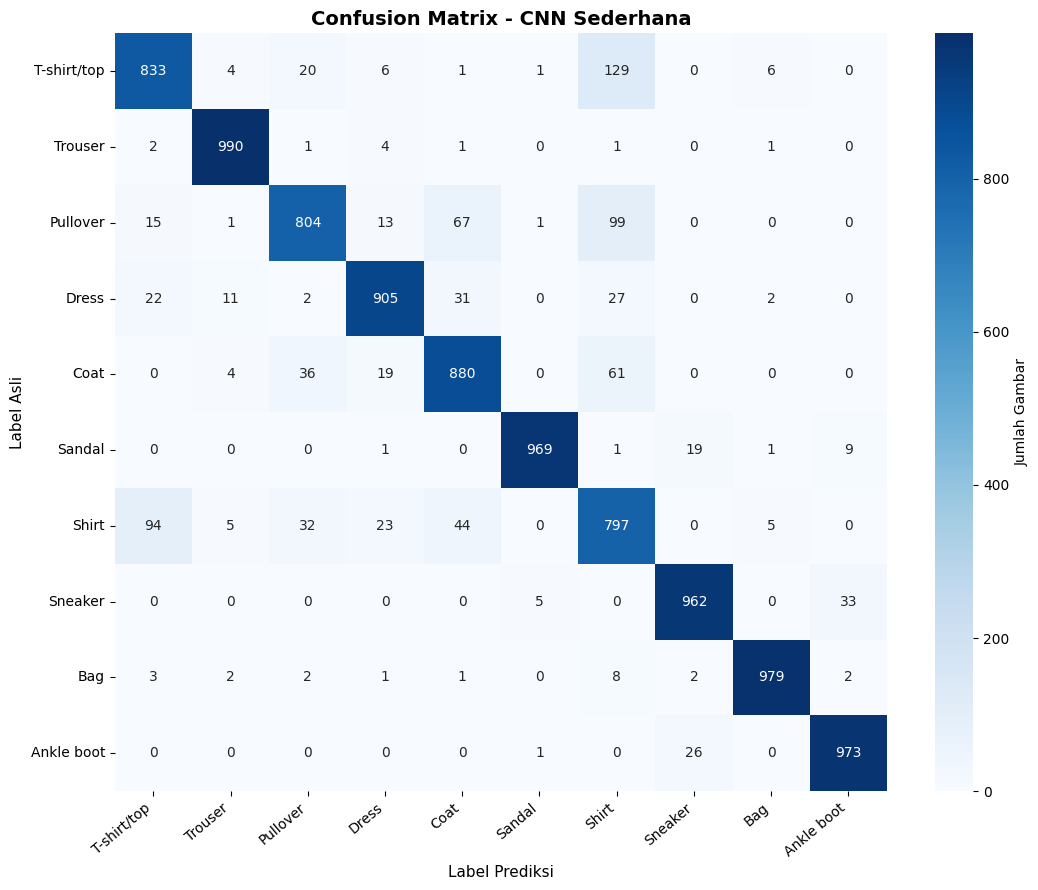

In [22]:
# Confusion Matrix 10x10 model terbaik
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=[class_names[i] for i in range(10)],
    yticklabels=[class_names[i] for i in range(10)],
    cbar_kws={'label': 'Jumlah Gambar'}
)
plt.title(f'Confusion Matrix - {best_name}', fontsize=14, fontweight='bold')
plt.xlabel('Label Prediksi', fontsize=11)
plt.ylabel('Label Asli', fontsize=11)
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Jumlah salah klasifikasi: 908 dari 10000 gambar (9.08%)


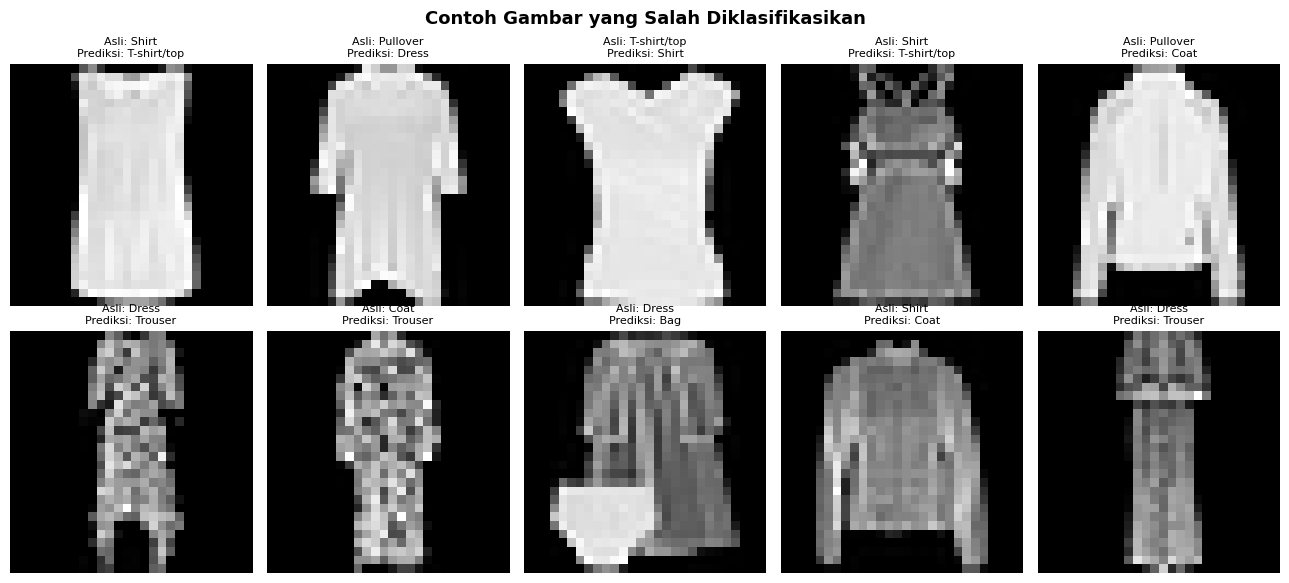

In [23]:
# Tampilkan contoh gambar yang salah diklasifikasikan oleh model terbaik
wrong_idx = np.where(best_pred != y_test)[0]
print(f"Jumlah salah klasifikasi: {len(wrong_idx)} dari {len(y_test)} gambar "
      f"({len(wrong_idx) / len(y_test) * 100:.2f}%)")

rng = np.random.default_rng(42)
sample_idx = rng.choice(wrong_idx, size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, idx in zip(axes.ravel(), sample_idx):
    ax.imshow(X_test_cnn[idx].reshape(28, 28), cmap='gray')
    ax.set_title(
        f"Asli: {class_names[y_test[idx]]}\nPrediksi: {class_names[best_pred[idx]]}",
        fontsize=8
    )
    ax.axis('off')
fig.suptitle('Contoh Gambar yang Salah Diklasifikasikan', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Layer konvolusi pertama : conv_1
Shape feature map       : (26, 26, 32)


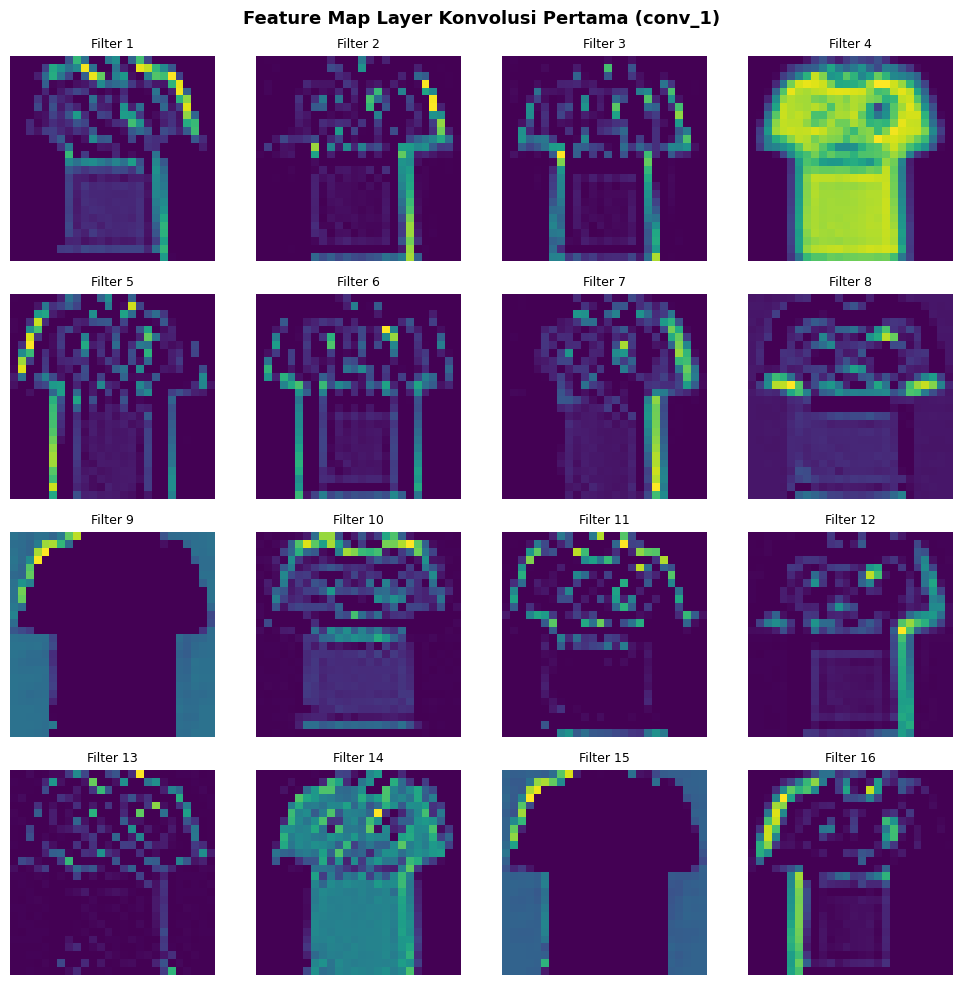

In [24]:
# Visualisasi feature map dari layer konvolusi pertama model terbaik
first_conv = next(l for l in best_model.layers if isinstance(l, layers.Conv2D))

feature_model = keras.Model(inputs=best_model.inputs, outputs=first_conv.output)
sample_img = X_test_cnn[0]
feature_maps = feature_model.predict(sample_img[np.newaxis, ...], verbose=0)[0]

print("Layer konvolusi pertama :", first_conv.name)
print("Shape feature map       :", feature_maps.shape)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[:, :, i], cmap='viridis')
    ax.set_title(f'Filter {i + 1}', fontsize=9)
    ax.axis('off')
fig.suptitle(f'Feature Map Layer Konvolusi Pertama ({first_conv.name})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [25]:
# Simpan model terbaik untuk digunakan pada tugas Deployment
best_model.save('model.keras')
ukuran_mb = os.path.getsize('model.keras') / (1024 * 1024)

print(f"Model terbaik ({best_name}) berhasil disimpan sebagai model.keras ({ukuran_mb:.2f} MB).")

Model terbaik (CNN Sederhana) berhasil disimpan sebagai model.keras (2.61 MB).


# 5. Analisis

## 5.1 Perbandingan Performa Ketiga Model

Evaluasi dilakukan pada 10.000 gambar test yang tidak pernah digunakan saat training maupun validasi. Hasil lengkapnya adalah sebagai berikut.

| Model | Accuracy | Precision (macro) | Recall (macro) | F1-Score (macro) | Jumlah Parameter |
|---|---|---|---|---|---|
| ANN Baseline | 88,34% | 88,62% | 88,34% | 0,8843 | 235.146 |
| CNN Sederhana | **90,92%** | **91,16%** | **90,92%** | **0,9098** | 225.034 |
| CNN + BatchNorm + Dropout | 90,78% | 90,83% | 90,78% | 0,9077 | 225.322 |

CNN Sederhana menjadi model terbaik dengan accuracy 90,92% dan F1-Score macro 0,9098. Model ini unggul 2,58 poin persentase atas ANN Baseline dan 0,14 poin persentase atas CNN + BatchNorm + Dropout. Selisih 0,14 poin antara kedua CNN sangat kecil dan berada dalam rentang variasi acak, sehingga secara praktis keduanya dapat dianggap setara; pemilihan CNN Sederhana sebagai model terbaik didasarkan pada F1-Score macro yang sedikit lebih tinggi.

## 5.2 Pengaruh Arsitektur dan Jumlah Parameter

Menariknya, ANN Baseline justru memiliki jumlah parameter paling banyak (235.146), lebih banyak daripada CNN Sederhana (225.034), tetapi performanya paling rendah. Hal ini menunjukkan bahwa jumlah parameter bukan satu-satunya penentu kualitas model. ANN menerima input yang sudah di-Flatten menjadi vektor 784 nilai, sehingga setiap piksel diperlakukan sebagai fitur yang independen dan hubungan spasial antar piksel (tepi, sudut, tekstur lokal) hilang. Akibatnya ANN harus mempelajari ulang pola visual dari kombinasi piksel yang sangat besar.

CNN memproses gambar dalam bentuk 28×28×1 sehingga informasi spasial tetap terjaga. Layer Conv2D 3×3 dengan weight sharing mendeteksi pola lokal (tepi dan tekstur) pada seluruh posisi gambar dengan jumlah bobot yang jauh lebih sedikit, lalu MaxPooling meringkas resolusi dan memberikan toleransi terhadap pergeseran kecil. Kombinasi inilah yang membuat CNN lebih efisien dan 2,58 poin persentase lebih akurat daripada ANN, meskipun parameternya lebih sedikit.

## 5.3 Analisis Learning Curve dan Overfitting

**ANN Baseline.** Accuracy training naik konsisten dari 81,54% pada epoch 1 menjadi 90,85% pada epoch 8, sedangkan accuracy validation tertahan di kisaran 87,5–87,7%. Validation loss mencapai minimum 0,3368 pada epoch 5 dan setelah itu kembali naik, sehingga EarlyStopping menghentikan training pada epoch 8 dan mengembalikan bobot epoch 5. Selisih train–validation pada akhir training sekitar 3,1 poin persentase. Pola ini menunjukkan overfitting ringan–sedang: model terus menghafal data training sementara kemampuannya pada data validation tidak lagi meningkat.

**CNN Sederhana.** Accuracy training mencapai 94,86% pada epoch 12, sedangkan validation 90,27%. Validation loss terbaik adalah 0,2619 pada epoch 9 (validation accuracy 90,62%), lalu EarlyStopping menghentikan training pada epoch 12 dan mengembalikan bobot epoch 9. Selisih train–validation di akhir training sekitar 4,6 poin persentase, lebih besar daripada ANN. Ini wajar karena CNN memiliki kapasitas yang lebih besar untuk mempelajari pola visual, sehingga lebih mudah overfitting ketika jumlah data terbatas dan tidak ada augmentasi. Meskipun demikian, nilai absolut accuracy validation CNN tetap lebih tinggi daripada ANN.

**CNN + BatchNorm + Dropout.** Accuracy training 93,00% dan validation 90,73% pada epoch 13, dengan selisih hanya sekitar 2,3 poin persentase. Validation loss terbaik 0,2685 tercapai pada epoch 10, dan training berhenti pada epoch 13. Batch Normalization menstabilkan distribusi aktivasi sehingga training lebih halus, sedangkan Dropout 0,4 sebelum layer output mencegah model terlalu bergantung pada neuron tertentu. Efeknya terlihat jelas: selisih train–validation menyempit dari 4,6 menjadi 2,3 poin persentase dibandingkan CNN Sederhana. Namun, validation accuracy model ini sempat berfluktuasi (turun ke 88,37% pada epoch 6 dan 89,27% pada epoch 12) karena sifat acak Dropout dan estimasi running statistics pada Batch Normalization.

## 5.4 Pengaruh Penambahan Layer, Batch Normalization, dan Dropout

Penambahan layer konvolusi memberikan peningkatan performa yang paling besar. Dengan parameter yang sedikit lebih sedikit, CNN mengungguli ANN sebesar 2,58 poin persentase karena mampu mengekstraksi fitur visual secara hierarkis: filter awal menangkap tepi dan tekstur, lalu filter berikutnya mengombinasikannya menjadi bentuk yang lebih kompleks.

Batch Normalization dan Dropout tidak meningkatkan accuracy test secara signifikan (90,78% versus 90,92%), tetapi keduanya berhasil memperkecil jarak train–validation. Artinya, regularisasi bekerja sesuai tujuannya untuk menekan overfitting, hanya saja CNN Sederhana belum mengalami overfitting yang parah sehingga manfaat regularisasi belum cukup besar untuk mengimbangi sedikit penurunan kapasitas model. Dengan kata lain, pada eksperimen ini terdapat trade-off: model CNN + BatchNorm + Dropout lebih stabil secara generalisasi (selisih train–validation lebih kecil), tetapi CNN Sederhana tetap memberikan skor test tertinggi.

## 5.5 Kelas yang Sulit Dibedakan

Dari 10.000 gambar test, model terbaik salah mengklasifikasikan 908 gambar (9,08%). Kesalahan terkonsentrasi pada kelompok pakaian atasan dan alas kaki:

- **Shirt** memiliki F1-Score terendah (0,7508; precision 0,7097; recall 0,7970). Sebanyak 94 gambar Shirt diprediksi sebagai T-shirt/top, 44 sebagai Coat, dan 32 sebagai Pullover. Sebaliknya, 129 gambar T-shirt/top, 99 Pullover, dan 61 Coat justru diprediksi sebagai Shirt. Kelas Shirt menjadi semacam "pusat" kebingungan untuk semua pakaian atasan.
- **Pullover** memiliki recall 0,8040 karena 99 gambar diprediksi sebagai Shirt dan 67 sebagai Coat. F1-Score-nya 0,8477.
- **T-shirt/top** memiliki F1-Score 0,8461, terutama karena 129 gambar tertukar dengan Shirt.
- **Coat** memiliki F1-Score 0,8691; 61 gambar diprediksi sebagai Shirt dan 36 sebagai Pullover. Selain itu, 31 gambar Dress juga diprediksi sebagai Coat.
- Pada alas kaki, Sneaker dan Ankle boot saling tertukar (33 Sneaker → Ankle boot dan 26 Ankle boot → Sneaker), sedangkan 19 Sandal diprediksi sebagai Sneaker. Bentuk profil ketiganya memang mirip.

Sebaliknya, kelas yang mudah dikenali adalah Trouser (F1 0,9817), Bag (F1 0,9819), Sandal (F1 0,9803), Ankle boot (F1 0,9648), dan Sneaker (F1 0,9577). Kesulitan pada pakaian atasan terjadi karena pada resolusi 28×28 piksel grayscale, perbedaan panjang lengan, kerah, dan bahan sulit terlihat sehingga siluet T-shirt, Shirt, Pullover, dan Coat tampak serupa. Pola ini konsisten dengan hasil EDA bahwa kelas-kelas tersebut memang mirip secara visual.

# 6. Kesimpulan dan Saran

## 6.1 Kesimpulan

Berdasarkan seluruh eksperimen yang telah dilakukan, dapat disimpulkan bahwa:

1. **CNN Sederhana adalah model terbaik** dengan accuracy 90,92%, precision macro 91,16%, recall macro 90,92%, dan F1-Score macro 0,9098 menggunakan 225.034 parameter. Model ini tersimpan sebagai `model.keras` (2,61 MB) untuk kebutuhan deployment.
2. **ANN Baseline memperoleh accuracy 88,34%** dengan 235.146 parameter. Meskipun parameternya paling banyak, ANN kalah karena operasi Flatten menghilangkan informasi spasial gambar.
3. **CNN + BatchNorm + Dropout memperoleh accuracy 90,78%** (F1 0,9077), sedikit di bawah CNN Sederhana, tetapi memiliki selisih train–validation paling kecil (sekitar 2,3 poin persentase dibandingkan 4,6 poin pada CNN Sederhana). Regularisasi terbukti menekan overfitting, meskipun belum meningkatkan skor test pada eksperimen ini.
4. **EarlyStopping bekerja baik** pada ketiga model. Training berhenti sebelum 20 epoch (epoch 8, 12, dan 13), sehingga waktu komputasi lebih efisien dan bobot terbaik tidak tertimpa oleh epoch yang sudah overfitting.
5. **Kesalahan terbesar terjadi pada kelompok pakaian atasan** (Shirt, T-shirt/top, Pullover, Coat) dan kelompok alas kaki (Sneaker, Ankle boot, Sandal) karena siluetnya sangat mirip pada resolusi rendah. Kelas Shirt adalah yang paling sulit dengan F1-Score 0,7508.

## 6.2 Saran

1. **Data augmentation** (rotasi kecil, pergeseran, zoom, dan horizontal flip) berpotensi menekan overfitting dan meningkatkan akurasi, terutama pada CNN Sederhana yang selisih train–validation-nya paling besar.
2. **Arsitektur yang lebih dalam** dengan GlobalAveragePooling, blok konvolusi tambahan, atau batch normalization tanpa Dropout dapat dicoba untuk meningkatkan kemampuan membedakan pakaian atasan.
3. **Tuning hyperparameter** seperti learning rate schedule, ukuran batch, laju Dropout (misalnya 0,2–0,3), dan jumlah filter perlu diuji lebih lanjut karena selisih kedua CNN sangat kecil dan kemungkinan dipengaruhi faktor acak.
4. **Melatih ulang dengan beberapa random seed** lalu melaporkan rata-rata dan simpangan baku akan membuat perbandingan antar model lebih meyakinkan, mengingat perbedaan 0,14 poin persentase berada di batas variasi antar-run.
5. Untuk **deployment**, CNN Sederhana dapat dipilih karena akurasinya tertinggi dan ukurannya kecil, sedangkan CNN + BatchNorm + Dropout dapat dipertimbangkan jika stabilitas dan ketahanan terhadap overfitting lebih diprioritaskan.